# Chapter 16 — Example 16.1
## Tabular Q-Learning Reinforcement Learning for Four-Bar Linkage Synthesis

This example implements a tabular Q-learning algorithm using a discrete table with NumPy to optimize the linkage lengths $[a, b, c, d]$ of the mechanism.

**Book:** *Four-Bar Linkage Synthesis with AI*

## 1. Setup and Environment Parameters

In [9]:
import numpy as np
import random

# Environment parameters
D_MIN, D_MAX = 0.5, 4.0
N_STATES  = 8
N_ACTIONS = 4

# Q-Learning Hyperparameters
ALPHA = 0.1
GAMMA = 0.9
EPS_START = 1.0
EPS_END = 0.05
EPS_DECAY = 0.995
N_EPISODES = 500
SEED = 42

# Random seed configuration
random.seed(SEED)
np.random.seed(SEED)

print('Parameters configured successfully.')

Parameters configured successfully.


### Explanation of the Q-Table Structure

In this optimization problem, the Q-table represents the action-value function $Q(s, a)$. Its structure is defined under the following principles:

1. **State Dimensions ($s$):**
   The state is defined by the current configuration of the 4 linkage lengths: $[a, b, c, d]$.
   Since each of these continuous variables is discretized into `N_STATES = 8` intervals or levels, the total size of the state space is:
   $$8 \times 8 \times 8 \times 8 = 4096 \text{ possible states}$$

2. **Action Dimensions ($a$):**
   In each state, the agent can take one of the `N_ACTIONS = 4` actions defined in `ACTIONS` (incrementing or decrementing the length of $a$ or $b$ by a discrete step `DELTA`):
   * **Action 0:** Increment linkage $a$ ($+a$)
   * **Action 1:** Decrement linkage $a$ ($-a$)
   * **Action 2:** Increment linkage $b$ ($+b$)
   * **Action 3:** Decrement linkage $b$ ($-b$)

3. **Initialization in NumPy:**
   The table is initialized entirely with zeros as a 5-dimensional array:
   ```python
   Q = np.zeros((N_STATES, N_STATES, N_STATES, N_STATES, N_ACTIONS))
   # Dimensions: (8, 8, 8, 8, 4)
   ```

4. **Access and Indexing:**
   To query or update a value, we convert the continuous lengths $[a, b, c, d]$ into discrete integer state indices using the `state_idx()` function (which maps values to the range $[0, 7]$).
   
   For example, to access the Q-value of the state indexed as `(s_a, s_b, s_c, s_d)` when taking action `act`:
   ```python
   s = state_idx(a, b, c, d) # Returns a tuple, e.g., (3, 5, 2, 4)
   q_value = Q[s][act]       # Equivalent to Q[3, 5, 2, 4, act]
   ```

## 2. Environment Definition: Kinematics and Reward Function

In [10]:
import numpy as np

def fk(a, b, c, d, n=40):
    """Simplified forward kinematics to obtain the trajectory."""
    th2 = np.linspace(0, 2*np.pi, n)
    X = a * np.cos(th2) + b * np.cos(th2 * 0.9 + 0.3)
    Y = a * np.sin(th2) + b * np.sin(th2 * 0.9 + 0.3)
    return X, Y

# Target reference trajectory
X_obj, Y_obj = fk(1.0, 2.5, 2.0, 2.8)

def state_idx(a, b, c, d):
    """Discretizes the continuous parameters into state indices."""
    def disc(v):
        return int(np.clip((v - D_MIN) / (D_MAX - D_MIN) * (N_STATES - 1), 0, N_STATES - 1))
    return (disc(a), disc(b), disc(c), disc(d))

def reward(a, b, c, d):
    """Calculates reward based on the mean Euclidean distance."""
    X, Y = fk(a, b, c, d)
    return -np.mean(np.sqrt((X - X_obj)**2 + (Y - Y_obj)**2))

# Step size and actions definition
DELTA = (D_MAX - D_MIN) / (N_STATES - 1)
ACTIONS = [
    (DELTA, 0, 0, 0),   # Action 0: +a
    (-DELTA, 0, 0, 0),  # Action 1: -a
    (0, DELTA, 0, 0),   # Action 2: +b
    (0, -DELTA, 0, 0)   # Action 3: -b
]

print(f'Target mechanism reward: {reward(1.0, 2.5, 2.0, 2.8):.6f}')

Target mechanism reward: -0.000000


## 3. Training with Tabular Q-Learning

In [11]:
import numpy as np
import random
import builtins

# Initialize the Q-table with zeros
Q = np.zeros((N_STATES, N_STATES, N_STATES, N_STATES, N_ACTIONS))
eps = EPS_START
hist = []

for ep in range(N_EPISODES):
    # Randomly initialize linkage state within the continuous range
    a = random.uniform(D_MIN, D_MAX)
    b = random.uniform(D_MIN, D_MAX)
    c = random.uniform(D_MIN, D_MAX)
    d = random.uniform(D_MIN, D_MAX)
    tot_r = 0.0

    for _ in range(50):
        s = state_idx(a, b, c, d)

        # Action selection using Epsilon-Greedy policy
        if random.random() < eps:
            act = random.randint(0, N_ACTIONS - 1)
        else:
            act = int(np.argmax(Q[s]))

        da, db, dc, dd = ACTIONS[act]

        # Apply action and clip to allowed [D_MIN, D_MAX] range
        a2 = np.clip(a + da, D_MIN, D_MAX)
        b2 = np.clip(b + db, D_MIN, D_MAX)
        c2 = np.clip(c + dc, D_MIN, D_MAX)
        d2 = np.clip(d + dd, D_MIN, D_MAX)

        # Evaluate reward and new discretized state
        r = reward(a2, b2, c2, d2)
        s2 = state_idx(a2, b2, c2, d2)

        # Bellman equation update for Q-Learning
        Q[s][act] += ALPHA * (r + GAMMA * np.max(Q[s2]) - Q[s][act])

        # State transition
        a, b, c, d = a2, b2, c2, d2
        tot_r += r

    hist.append(tot_r / 50)
    # Exploration rate decay (Epsilon)
    eps = builtins.max(EPS_END, eps * EPS_DECAY)

# Analyze training results
best_ep = builtins.min(range(N_EPISODES), key=lambda i: -hist[i])
print(f'Episode with the highest reward: {best_ep + 1}')
print(f'Final average reward (last 20 ep.): {np.mean(hist[-20:]):.4f}')
print(f'Final epsilon: {eps:.4f}')

Episode with the highest reward: 435
Final average reward (last 20 ep.): -0.5513
Final epsilon: 0.0816


## 4. Visualizing the Learning History

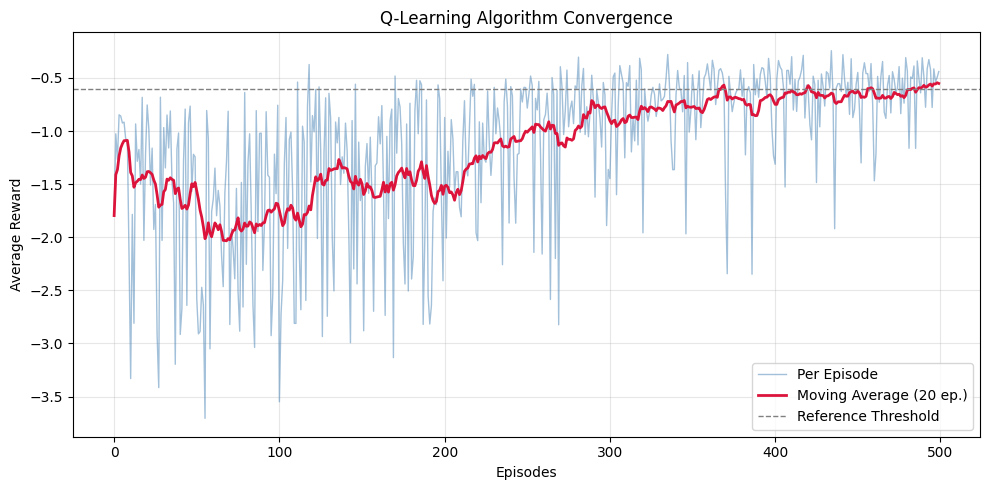

In [12]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Create figure to plot convergence
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(hist, color='steelblue', alpha=0.5, lw=1, label='Per Episode')

# Curve smoothing via moving average using pandas
window_size = 20
smooth = pd.Series(hist).rolling(window=window_size, min_periods=1).mean().values

ax.plot(smooth, color='crimson', lw=2, label=f'Moving Average ({window_size} ep.)')
ax.axhline(-0.6, color='gray', ls='--', lw=1, label='Reference Threshold')

# Label settings and plot layout
ax.set_xlabel('Episodes')
ax.set_ylabel('Average Reward')
ax.set_title('Q-Learning Algorithm Convergence')
ax.legend(loc='best')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()